# Toronto_3D Quantization Debugging

Quantization can change weights and intermediate activations, which may affect predictions. This notebook uses ONNX Runtime's `qdq_loss_debug` APIs to match float32 and W8A8 tensors, measure their differences, and identify likely error hotspots.

The debugging APIs expose intermediate tensors and can use additional memory. This notebook runs on a small, fixed set of Toronto tiles and saves augmented debug models separately; it never overwrites the original ONNX artifacts.

Workflow:
1. Validate the float and QDQ ONNX models and their input/output signatures.
2. Match and rank corresponding weights.
3. Expose intermediate activations in temporary augmented models.
4. Collect both models' activations on identical representative inputs.
5. Match activations, measure error, and inspect the largest differences.

A large tensor error is a clue, not by itself proof that a layer causes accuracy loss. Correlate hotspots with output changes and held-out metrics before changing quantization.

In [1]:
import os
import sys
import tempfile
from pathlib import Path
from collections import Counter

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import onnx
import onnxruntime as ort
from onnxruntime.quantization.qdq_loss_debug import (
    collect_activations,
    create_activation_matching,
    create_weight_matching,
    modify_model_output_intermediate_tensors,
)

from src.quantize_toronto import TorontoCalibrationReader

DATA_DIR = Path("data/Toronto_3D")
ONNX_DIR = Path("outputs/toronto_onnx")
FLOAT_MODEL = ONNX_DIR / "pointnet_toronto_fp32_prep.onnx"
QUANT_MODEL = ONNX_DIR / "pointnet_toronto_w8a8_perchannel.onnx"
CALIBRATION_SCANS = [DATA_DIR / "L001.ply"]
N_POINTS = 2048
TILE_SIZE = 20.0
COORD_SCALE = 25.0
N_CALIBRATION_TILES = 4

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
print("Project root:", ROOT)

Project root: /Users/wawclpy/Documents/pointcloud-seg-edge


## 1. Import dependencies and configure model paths

Use the prepared FP32 graph as the reference and a W8A8 QDQ graph as the comparison. Calibration inputs must follow the training/inference preprocessing and have the same fixed point count. The default calibration set is intentionally small to keep intermediate-tensor collection manageable.

In [2]:
missing_models = [str(path) for path in (FLOAT_MODEL, QUANT_MODEL) if not path.is_file()]
if missing_models:
    raise FileNotFoundError(
        "Required ONNX model(s) missing: " + ", ".join(missing_models)
        + ". Export the Toronto model and run src.quantize_toronto first."
    )
missing_scans = [str(path) for path in CALIBRATION_SCANS if not path.is_file()]
if missing_scans:
    raise FileNotFoundError("Calibration scan(s) missing: " + ", ".join(missing_scans))

float_onnx = onnx.load(str(FLOAT_MODEL))
quant_onnx = onnx.load(str(QUANT_MODEL))
onnx.checker.check_model(float_onnx)
onnx.checker.check_model(quant_onnx)


def io_signature(model):
    return {
        "inputs": [(value.name, [d.dim_value or d.dim_param for d in value.type.tensor_type.shape.dim])
                   for value in model.graph.input],
        "outputs": [(value.name, [d.dim_value or d.dim_param for d in value.type.tensor_type.shape.dim])
                    for value in model.graph.output],
    }

float_signature = io_signature(float_onnx)
quant_signature = io_signature(quant_onnx)
print("FP32:", float_signature)
print("QDQ: ", quant_signature)
assert float_signature["inputs"] == quant_signature["inputs"], "Model input signatures differ"
assert float_signature["outputs"] == quant_signature["outputs"], "Model output signatures differ"
print("Input/output signatures match; exported input is fixed batch-1.")

FP32: {'inputs': [('points', [1, 4, 2048])], 'outputs': [('logits', [1, 9, 2048])]}
QDQ:  {'inputs': [('points', [1, 4, 2048])], 'outputs': [('logits', [1, 9, 2048])]}
Input/output signatures match; exported input is fixed batch-1.


## 2. Load the float32 and quantized models

ONNX Runtime can execute both original models with the CPU provider. First inspect their graph operators and verify the common external interface. Static exported PointNet uses input `points` shaped `(1, 4, N)` and output `logits` shaped `(1, 9, N)`.

In [3]:
float_ops = Counter(node.op_type for node in float_onnx.graph.node)
quant_ops = Counter(node.op_type for node in quant_onnx.graph.node)
print("FP32 operators:", float_ops)
print("QDQ operators:", quant_ops)

float_session = ort.InferenceSession(str(FLOAT_MODEL), providers=["CPUExecutionProvider"])
quant_session = ort.InferenceSession(str(QUANT_MODEL), providers=["CPUExecutionProvider"])
print("ORT inputs:", [(i.name, i.shape, i.type) for i in float_session.get_inputs()])
print("ORT outputs:", [(o.name, o.shape, o.type) for o in float_session.get_outputs()])

FP32 operators: Counter({'Conv': 7, 'Relu': 6, 'ReduceMax': 1, 'Expand': 1, 'Concat': 1})
QDQ operators: Counter({'DequantizeLinear': 24, 'QuantizeLinear': 10, 'Conv': 7, 'ReduceMax': 1, 'Expand': 1, 'Concat': 1})
ORT inputs: [('points', [1, 4, 2048], 'tensor(float)')]
ORT outputs: [('logits', [1, 9, 2048], 'tensor(float)')]


## 3. Match model weights

`create_weight_matching()` pairs corresponding float and dequantized QDQ weights. Compare tensors with matching shapes; report maximum absolute error, RMSE, and cosine similarity. Some extra entries (such as bias/combined parameter records) may not be directly comparable as simple weight arrays, so the code checks shape and available keys.

In [4]:
weight_matching = create_weight_matching(str(FLOAT_MODEL), str(QUANT_MODEL))
print("weight matches:", len(weight_matching))
print("example keys:", list(weight_matching)[:8])


def tensor_metrics(reference, candidate):
    a = np.asarray(reference, dtype=np.float64).reshape(-1)
    b = np.asarray(candidate, dtype=np.float64).reshape(-1)
    if a.shape != b.shape or a.size == 0:
        return None
    diff = a - b
    denom = np.linalg.norm(a) * np.linalg.norm(b)
    cosine = float(np.dot(a, b) / denom) if denom else float("nan")
    signal = np.mean(a * a)
    noise = np.mean(diff * diff)
    sqnr_db = float(10 * np.log10(signal / noise)) if noise > 0 and signal > 0 else float("inf")
    return {
        "max_abs": float(np.max(np.abs(diff))),
        "rmse": float(np.sqrt(noise)),
        "cosine": cosine,
        "sqnr_db": sqnr_db,
        "n_values": int(a.size),
    }

weight_rows = []
for name, match in weight_matching.items():
    if "float" not in match or "dequantized" not in match:
        continue
    metrics = tensor_metrics(match["float"], match["dequantized"])
    if metrics is not None:
        weight_rows.append({"tensor": name, **metrics})
weight_rows.sort(key=lambda row: row["rmse"], reverse=True)
print("comparable matched weights:", len(weight_rows))
for row in weight_rows[:10]:
    print(f"{row['tensor']:40s} max={row['max_abs']:.5g} RMSE={row['rmse']:.5g} "
          f"cos={row['cosine']:.5f} SQNR={row['sqnr_db']:.1f} dB")

weight matches: 14
example keys: ['glob.0.0.weight_bias', 'glob.0.0.weight', 'glob.1.0.weight_bias', 'glob.1.0.weight', 'head.0.0.weight_bias', 'head.0.0.weight', 'head.1.0.weight_bias', 'head.1.0.weight']
comparable matched weights: 14
local.0.0.weight                         max=0.03431 RMSE=0.010197 cos=1.00000 SQNR=50.0 dB
local.1.0.weight                         max=0.0025553 RMSE=0.00093138 cos=0.99999 SQNR=47.6 dB
glob.0.0.weight                          max=0.0021163 RMSE=0.00084269 cos=0.99999 SQNR=47.4 dB
glob.1.0.weight                          max=0.0014484 RMSE=0.00056128 cos=0.99999 SQNR=46.5 dB
head.1.0.weight                          max=0.0011638 RMSE=0.00037032 cos=0.99999 SQNR=45.4 dB
head.3.weight                            max=0.0007591 RMSE=0.00034416 cos=0.99999 SQNR=46.1 dB
head.0.0.weight                          max=0.00096999 RMSE=0.00034308 cos=0.99998 SQNR=44.2 dB
local.0.0.weight_bias                    max=0.00013133 RMSE=6.6191e-05 cos=1.00000 SQNR=75.8 

## 4. Expose intermediate activations

The API creates augmented copies with graph intermediates added as outputs. These files can be large and are for diagnosis only. Keep them separate from deployment models; a temporary directory is used here.

In [5]:
debug_dir = Path(tempfile.mkdtemp(prefix="toronto_qdq_debug_"))
FLOAT_AUGMENTED = debug_dir / "float_intermediates.onnx"
QUANT_AUGMENTED = debug_dir / "qdq_intermediates.onnx"

modify_model_output_intermediate_tensors(str(FLOAT_MODEL), str(FLOAT_AUGMENTED))
modify_model_output_intermediate_tensors(str(QUANT_MODEL), str(QUANT_AUGMENTED))
print("Augmented FP32 model:", FLOAT_AUGMENTED, f"({FLOAT_AUGMENTED.stat().st_size/1024:.1f} KB)")
print("Augmented QDQ model: ", QUANT_AUGMENTED, f"({QUANT_AUGMENTED.stat().st_size/1024:.1f} KB)")

Augmented FP32 model: /var/folders/gy/r8bd_ggn4k91x5yx004brvrw0000gr/T/toronto_qdq_debug_uhlwvxsr/float_intermediates.onnx (662.6 KB)
Augmented QDQ model:  /var/folders/gy/r8bd_ggn4k91x5yx004brvrw0000gr/T/toronto_qdq_debug_uhlwvxsr/qdq_intermediates.onnx (207.9 KB)


## 5. Collect activations from both models

`TorontoCalibrationReader` produces model inputs shaped `(1, 4, N)`. Rewind it before each model so the float and QDQ graphs see identical examples in identical order. Keeping only a few tiles controls the size of saved intermediate tensors.

In [6]:
reader = TorontoCalibrationReader(
    CALIBRATION_SCANS,
    n_points=N_POINTS,
    tile_size=TILE_SIZE,
    coord_scale=COORD_SCALE,
    max_tiles=N_CALIBRATION_TILES,
    seed=123,
)

reader.rewind()
float_activations = collect_activations(str(FLOAT_AUGMENTED), reader)
reader.rewind()
quant_activations = collect_activations(str(QUANT_AUGMENTED), reader)
print("float activation tensors:", len(float_activations))
print("quant activation tensors:", len(quant_activations))
print("example float tensors:", list(float_activations)[:10])

float activation tensors: 17
quant activation tensors: 35
example float tensors: ['getitem_15', 'getitem_12', 'getitem_9', 'relu', 'relu_3', 'amax', 'relu_4', 'points', 'getitem_6', 'logits']


## 6. Match and compare activations

`create_activation_matching()` returns entries for float activations and QDQ activations, including QDQ inputs (`pre_qdq`) and outputs (`post_qdq`). The comparison below uses the matched float tensor against the quantized graph's **post-QDQ** tensor where available. That measures the value delivered onward after quantize/dequantize, not just the pre-quantized activation.

In [7]:
activation_matching = create_activation_matching(quant_activations, float_activations)
print("matched activation entries:", len(activation_matching))
print("example matched names:", list(activation_matching)[:12])

activation_rows = []
for name, match in activation_matching.items():
    float_values = match.get("float")
    quant_values = match.get("post_qdq")
    if float_values is None or quant_values is None:
        continue
    for sample_i, (float_tensor, quant_tensor) in enumerate(zip(float_values, quant_values)):
        metrics = tensor_metrics(float_tensor, quant_tensor)
        if metrics is not None:
            activation_rows.append({"tensor": name, "sample": sample_i, **metrics})

activation_rows.sort(key=lambda row: row["rmse"], reverse=True)
print("comparable activation tensors:", len(activation_rows))
for row in activation_rows[:15]:
    print(f"{row['tensor']:40s} sample={row['sample']} max={row['max_abs']:.5g} "
          f"RMSE={row['rmse']:.5g} cos={row['cosine']:.5f} SQNR={row['sqnr_db']:.1f} dB")

matched activation entries: 10
example matched names: ['logits', 'relu_3', 'cat', 'relu_4', 'relu_5', 'expand', 'points', 'relu_2', 'relu_1', 'relu']
comparable activation tensors: 40
logits                                   sample=0 max=0.12693 RMSE=0.059507 cos=0.99983 SQNR=33.4 dB
logits                                   sample=1 max=0.10833 RMSE=0.037109 cos=0.99980 SQNR=33.5 dB
expand                                   sample=2 max=0.1506 RMSE=0.033127 cos=0.99991 SQNR=37.7 dB
expand                                   sample=3 max=0.10175 RMSE=0.032726 cos=0.99985 SQNR=35.1 dB
logits                                   sample=3 max=0.11126 RMSE=0.030481 cos=0.99990 SQNR=36.8 dB
cat                                      sample=2 max=0.1506 RMSE=0.03048 cos=0.99991 SQNR=37.5 dB
cat                                      sample=3 max=0.10175 RMSE=0.030269 cos=0.99984 SQNR=34.9 dB
expand                                   sample=1 max=0.14641 RMSE=0.029984 cos=0.99981 SQNR=34.1 dB
cat        

## 7. Identify error hotspots and guide quantization changes

Rank errors across calibration tiles and plot the largest layer-wise RMSE values. Weight errors are parameter-level clues; activation errors show where differences appear during these particular inputs. Candidate follow-ups include per-tensor versus per-channel quantization, percentile/entropy calibration, or excluding a sensitive node, followed by re-quantization and held-out evaluation.


Layer ranking (highest mean RMSE first):
logits                                   RMSE=0.038508 max=0.12693 cosine=0.99987 worst-SQNR=33.4 dB
expand                                   RMSE=0.030747 max=0.1506 cosine=0.99962 worst-SQNR=26.6 dB
cat                                      RMSE=0.028644 max=0.1506 cosine=0.99963 worst-SQNR=26.9 dB
relu_3                                   RMSE=0.024256 max=0.21086 cosine=0.99930 worst-SQNR=26.6 dB
relu_4                                   RMSE=0.021948 max=0.13345 cosine=0.99983 worst-SQNR=32.9 dB
relu_5                                   RMSE=0.021615 max=0.12079 cosine=0.99980 worst-SQNR=31.2 dB
relu_2                                   RMSE=0.019608 max=0.13936 cosine=0.99947 worst-SQNR=28.1 dB
relu_1                                   RMSE=0.015759 max=0.097654 cosine=0.99962 worst-SQNR=29.4 dB
relu                                     RMSE=0.010814 max=0.065214 cosine=0.99983 worst-SQNR=30.6 dB
points                                   RMSE=0.0

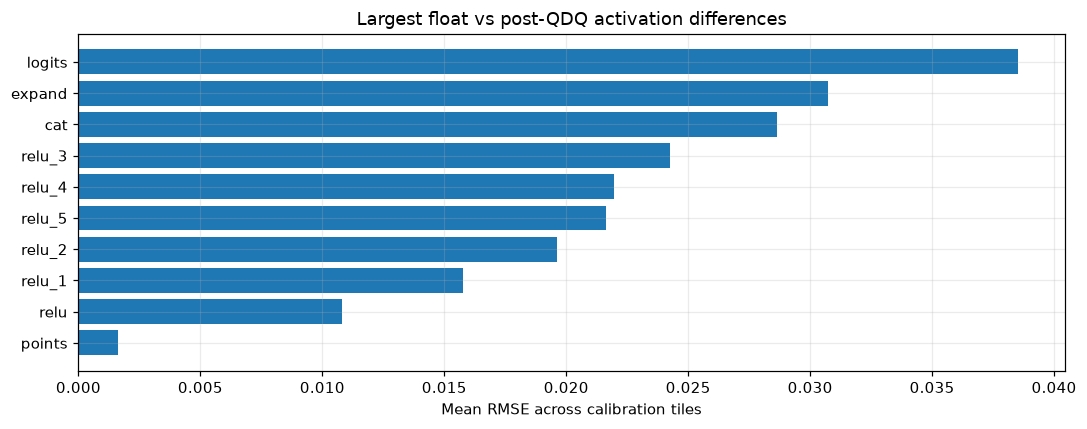


Largest pre-QDQ vs post-QDQ errors:
relu_4                                   sample=0 RMSE=2.4522 SQNR=2.1 dB
relu_4                                   sample=2 RMSE=1.7142 SQNR=2.1 dB
relu_5                                   sample=0 RMSE=1.6937 SQNR=3.5 dB
relu_4                                   sample=1 RMSE=1.4231 SQNR=2.0 dB
relu_5                                   sample=2 RMSE=1.3238 SQNR=3.4 dB
relu_4                                   sample=3 RMSE=1.2094 SQNR=2.2 dB
relu_5                                   sample=1 RMSE=0.89764 SQNR=2.9 dB
relu_1                                   sample=2 RMSE=0.83258 SQNR=1.7 dB
relu_5                                   sample=3 RMSE=0.77566 SQNR=3.4 dB
relu                                     sample=3 RMSE=0.77422 SQNR=3.0 dB


In [8]:
if activation_rows:
    # Aggregate each activation tensor across calibration tiles for a more stable ranking.
    by_tensor = {}
    for row in activation_rows:
        by_tensor.setdefault(row["tensor"], []).append(row)
    activation_summary = []
    for name, rows_for_name in by_tensor.items():
        activation_summary.append({
            "tensor": name,
            "max_abs": max(row["max_abs"] for row in rows_for_name),
            "mean_rmse": float(np.mean([row["rmse"] for row in rows_for_name])),
            "min_sqnr_db": min(row["sqnr_db"] for row in rows_for_name),
            "mean_cosine": float(np.nanmean([row["cosine"] for row in rows_for_name])),
        })
    activation_summary.sort(key=lambda row: row["mean_rmse"], reverse=True)
    print("\nLayer ranking (highest mean RMSE first):")
    for row in activation_summary:
        print(f"{row['tensor']:40s} RMSE={row['mean_rmse']:.5g} "
              f"max={row['max_abs']:.5g} cosine={row['mean_cosine']:.5f} "
              f"worst-SQNR={row['min_sqnr_db']:.1f} dB")

    top = activation_summary[:12]
    plt.figure(figsize=(10, max(4, 0.35 * len(top))))
    plt.barh([row["tensor"] for row in top][::-1], [row["mean_rmse"] for row in top][::-1])
    plt.xlabel("Mean RMSE across calibration tiles")
    plt.title("Largest float vs post-QDQ activation differences")
    plt.tight_layout()
    plt.show()
else:
    print("No matched float/post-QDQ activation pairs. Inspect activation_matching keys and ONNX graph naming.")

# Within-QDQ pre/post comparison isolates the rounding/clipping introduced at Q/DQ boundaries.
qdq_boundary_rows = []
for name, match in activation_matching.items():
    pre_values, post_values = match.get("pre_qdq"), match.get("post_qdq")
    if pre_values is None or post_values is None:
        continue
    for sample_i, (pre, post) in enumerate(zip(pre_values, post_values)):
        metrics = tensor_metrics(pre, post)
        if metrics is not None:
            qdq_boundary_rows.append({"tensor": name, "sample": sample_i, **metrics})
qdq_boundary_rows.sort(key=lambda row: row["rmse"], reverse=True)
print("\nLargest pre-QDQ vs post-QDQ errors:")
for row in qdq_boundary_rows[:10]:
    print(f"{row['tensor']:40s} sample={row['sample']} RMSE={row['rmse']:.5g} "
          f"SQNR={row['sqnr_db']:.1f} dB")